# Benchmarking Rust vs Python Mofography Periodic Segmentation Workflow
## Key points
- We need to make the playing field even. Essentially, allocating the same resources for both Rust and Python functions.
    - One cpu (core) and same number of threads per job.
    - One job is everything needed for one material. One dgrid calculation, and one do_periodic_segmentation call.
- Functions for Python: dgrid_from_atoms_cpu, do_periodic_segmentation
- Functions for Rust: dgrid_from_atoms_rust, do_periodic_segmentation_rust

**IMPORTANT NOTE**
- The Python functions are no slouch. If we let it, the dgrid calculation will run over all the cores also the connections calculation in python uses the ThreadPoolExecutor, so that could also run over ncores * nthreads in a node if we allow it. So, we need to wrap the dgrid in a wrapper function to stop it from using all the cores, and then wrap the wrapper in dask to make sure connections computing wont' use all the threads on all the cores, ensuring both run over the same resources, one core and N threads per core per material.
- So please make sure that all cpus are on the same node to avoid data transfer bottlenecks, and ncores = n_workers in the dask cluster when you run the workflow, then we can say we used 1 core per material. 


## There are a few more useful things in thie notebook, 
- It is painful to sample a set of ASE atoms from large ZIP full of 1000s of cif files. Especially when CIFs are big. So we'll put them in a parquet file (compressed), pick cifs first, then read in parallel spamming many dask workers, since each operation takes only little memory. See the details below.
- A function to plot whatever index material from the results list
- A function to plot dgrid_time and seg_time vs num_atoms, for rust vs python. 

## Grab a representatative subset of ASE atoms
When working with thousands of CIF files stored in a ZIP archive, extracting and parsing each file individually is extremely slow and I/O-bound. Each random access requires decompressing and reading from the archive, which does not scale well for large datasets. By converting all CIFs into a compressed Parquet DataFrame containing the raw CIF strings, we enable fast, parallel, and random access to any subset of structures. This approach dramatically reduces overhead and makes it practical to sample and process hundreds or thousands of structures efficiently, as demonstrated in the next cells.

### Convert zip file into easily searchable Parquet
The next cell demonstrates how to efficiently convert all CIF files from the `Tobacco.zip` archive into a compressed Parquet DataFrame containing the CIF strings. This approach allows for much faster loading and random access to CIF data in future analyses, compared to repeatedly extracting and parsing files from the ZIP archive. The cell uses parallel extraction with `ThreadPoolExecutor` and saves the resulting DataFrame with Zstd compression for optimal storage efficiency.

In [ ]:
import pandas as pd
from concurrent.futures import ThreadPoolExecutor
import zipfile

# Step 1: Extract CIF strings from ZIP in parallel
with zipfile.ZipFile('Tobacco.zip') as zf:
    cif_files = [f for f in zf.namelist() if f.lower().endswith('.cif')]
    
    def extract_cif_string(cif_file):
        with zf.open(cif_file) as f:
            cif_bytes = f.read()
            return cif_bytes.decode('latin-1')  # Use latin-1 to handle any encoding
    
    with ThreadPoolExecutor(max_workers=4) as executor:  # Adjust workers based on your CPU
        cif_strings = list(executor.map(extract_cif_string, cif_files))

# Step 2: Store in DataFrame
data = {
    'name': [f.replace('.cif', '') for f in cif_files],  # Remove .cif extension
    'cif': cif_strings
}
df = pd.DataFrame(data)

# Step 3: Save to compressed Parquet file with Zstd for max compression
df.to_parquet('tobacco_cifs.parquet', compression='zstd', index=False)
print(f"Converted {len(df)} CIF files to compressed Parquet dataframe with strings.")

### Random sample from Parquet file
This is an annoying step, because these CIF files are huge, its better to sample first and then read and convert them into ase atoms objects. This is a low memory operation, so we'll throw a lot of dask workers at them and read them as ase atoms objects rather quickly. 

#### Make imports

In [42]:
# Alternative fast loading: Use the pre-converted Parquet dataframe with CIF strings
# Run this instead of the slow ZIP reading cells above
import pandas as pd
from dask import delayed
import dask
from dask.distributed import progress, Client
import warnings
from ase.io import read
from io import  BytesIO
import os
num_rayon_threads = 4
os.environ["RAYON_NUM_THREADS"] = f"{num_rayon_threads}"


In [43]:
import mgr_rust
mgr_rust.rayon_num_threads()
print(f"Using {mgr_rust.rayon_num_threads()} threads for parallel processing")


Using 16 threads for parallel processing


[RAYON] current_num_threads = 16
[RAYON] current_num_threads = 16
16
[RAYON] current_num_threads = 16


### Set N 
How many to sample form the parquet

In [44]:
# Sample N random rows
N = 10  # Adjust as needed

#### Start local cluster
Put a large number of workers here to speed up the file reading. Each of it takes only a small amount of RAM so we can spam workers to get the files read into ASE atoms quickly.

In [4]:

# client.shutdown()
client = Client(n_workers=25)


2025-09-10 23:23:46,380 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:40073' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'cif_string_to_atoms-4b0e5391-8a22-4f35-93e4-4f8817338556'} (stimulus_id='handle-worker-cleanup-1757526826.3798938')
2025-09-10 23:23:46,385 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:41669' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'cif_string_to_atoms-4803098a-44d8-4202-a766-a13958d6afd5'} (stimulus_id='handle-worker-cleanup-1757526826.3856754')
2025-09-10 23:23:46,385 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:41669' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {'cif_string_to_atoms-4803098a-44d8-4202-a766-a13958d6afd5'} (stimulus_id='handle-worker-cleanup-1757526826.3856754')
2025-09-10 23:23:46,391 - distributed.scheduler - WARNING - Removing worker 'tc

In [5]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 25
Total threads: 25,Total memory: 14.92 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:32817,Workers: 25
Dashboard: http://127.0.0.1:8787/status,Total threads: 25
Started: Just now,Total memory: 14.92 GiB
Comm: tcp://127.0.0.1:39833,Total threads: 1
Dashboard: http://127.0.0.1:38017/status,Memory: 610.96 MiB
Nanny: tcp://127.0.0.1:44477,


### Read and convert to ase atoms objects

In [6]:
# Suppress warnings
warnings.filterwarnings('ignore')

# Load the compressed dataframe
df = pd.read_parquet('tobacco_cifs.parquet')


random_rows = df.sample(N, random_state=42)  # Use random_state for reproducibility

# Function to parse CIF string to atoms
def cif_string_to_atoms(cif_string):
    cif_bytes = cif_string.encode('latin-1')  # Use latin-1 for consistency
    return read(BytesIO(cif_bytes), format='cif')

# Parse selected CIF strings to atoms in parallel using Dask delayed (integrates with client)
cif_strings = random_rows['cif']  # Iterate directly without .tolist() for memory efficiency
atoms_delayed = [delayed(cif_string_to_atoms)(cif_str) for cif_str in cif_strings]
futures = dask.persist(*atoms_delayed)
progress(futures)


VBox()

/home/arung014/miniforge3/envs/llamp/lib/python3.13/site-packages/ase/io/cif.py:410: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(
/home/arung014/miniforge3/envs/llamp/lib/python3.13/site-packages/ase/io/cif.py:410: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(
/home/arung014/miniforge3/envs/llamp/lib/python3.13/site-packages/ase/io/cif.py:410: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(
/home/arung014/miniforge3/envs/llamp/lib/python3.13/site-packages/ase/io/cif.py:410: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(
/home/arung014/miniforge3/envs/llamp/lib/python3.13/

wait for the reading to finish... it should be fast. 

##### Get ase atoms objects

In [7]:

collected_futures = client.compute(futures)
# note to self: make sure to add None if atoms are not read correctly. otherwise we woulnd't know which atom is which.
atoms_list = [f.result() if f.status=='finished' else None for f in collected_futures]

print(f"Loaded and parsed {len(atoms_list)} random atoms from Parquet CIF strings (fast!).This many are None: {sum([1 for a in atoms_list if a is None])}")

Loaded and parsed 10 random atoms from Parquet CIF strings (fast!).This many are None: 0


### Segmentation Wrappers
Lets wrap around segmentation functions to grab the logging output and convert them into separate times for each step of the workflow (maxima detection, pbc segemtnation, no pbc, connections, reindexing etc) and store them along with the outputs. 

In [22]:
import logging
from io import StringIO
import time
import mofography as mgr
logging.basicConfig(level=logging.INFO)

def wrapper_segmentation_rust(index, mat_atoms, spacing):
    # Time dgrid computation
    dgrid_start = time.time()
    dgrid = mgr.dgrid_from_atoms_rust(mat_atoms, spacing=spacing)
    dgrid_time = time.time() - dgrid_start
    
    # Set up logging capture for segmentation
    log_capture_string = StringIO()
    ch = logging.StreamHandler(log_capture_string)
    ch.setLevel(logging.INFO)
    logger = logging.getLogger('mofography.rust_fun')
    logger.addHandler(ch)

    logger.setLevel(logging.INFO)
    logger.info(f"Starting segmentation for material index {index}")
    # Time segmentation
    seg_start = time.time()
    result = mgr.do_periodic_segmentation_rust(dgrid, mat_atoms, spacing=spacing, extra_padding=0, return_dgrid=True)
    seg_time = time.time() - seg_start
    
    # Get logs
    log_contents = log_capture_string.getvalue()
    logger.removeHandler(ch)
    
    # Add to result
    result['logs'] = log_contents
    # these are key! 
    result['material_index'] = index
    result['version'] = 'Rust'
    result['dgrid_time'] = dgrid_time
    result['seg_time'] = seg_time
    result['num_atoms'] = len(mat_atoms)
    
    return result

def wrapper_segmentation_python(index, mat_atoms, spacing):
    # Time dgrid computation
    dgrid_start = time.time()
    dgrid = mgr.dgrid_from_atoms_cpu(mat_atoms, spacing=spacing)
    dgrid_time = time.time() - dgrid_start
    
    # Set up logging capture for segmentation
    log_capture_string = StringIO()
    ch = logging.StreamHandler(log_capture_string)
    ch.setLevel(logging.INFO)
    logger = logging.getLogger('mofography.rust_fun')
    logger.addHandler(ch)
    logger.setLevel(logging.INFO)
    
    # Time segmentation
    seg_start = time.time()
    result = mgr.do_periodic_segmentation(dgrid, mat_atoms, spacing=spacing, extra_padding=0)
    seg_time = time.time() - seg_start
    
    # Get logs
    log_contents = log_capture_string.getvalue()
    logger.removeHandler(ch)
    
    # Add to result
    result['logs'] = log_contents
    # these are key! 
    result['material_index'] = index
    result['version'] = 'Python'
    result['dgrid_time'] = dgrid_time
    result['seg_time'] = seg_time
    result['num_atoms'] = len(mat_atoms)
    
    return result

### Reassign workers
Now that we are done iwth reading in the CIFs, we need to reassign the workers to have more RAM per worker to do the actual compute. Lets do the default n workers ( 4  cpus or cores on my laptop). Change as needed as per your system. when running on a cluster put all cpus in the same node, that should make data transfer easy. 

In [45]:
client.shutdown() # shutdown old client
client = Client() # keep default on laptop, on cluster use num_cpus. 

In [46]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 14.92 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42337,Workers: 4
Dashboard: http://127.0.0.1:8787/status,Total threads: 16
Started: Just now,Total memory: 14.92 GiB
Comm: tcp://127.0.0.1:32927,Total threads: 4
Dashboard: http://127.0.0.1:34371/status,Memory: 3.73 GiB
Nanny: tcp://127.0.0.1:41579,


## Benchmarking
Well breakdown the flow into two 1. dgrid computing and 2. periodic segmentation

### RUst benchmarking

In [47]:
delayed_results_rust= []
spacing = 0.5
for i, mat_atoms in enumerate(atoms_list):
    delayed_results_rust.append(delayed(wrapper_segmentation_rust)(i, mat_atoms, spacing))

Test one calculation

In [48]:
print(delayed_results_rust[0].compute()['logs'])

[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
/mnt/windows/Users/arung/shared_cloned_repos/repos/mofography_clones/mofography_rust2/mofography/mofography/helper.py:527: RuntimeWarning: overflow encountered in scalar subtract
  pos_minus[dim] = max(pos_minus[dim] - 1, 0)
/mnt/windows/Users/arung/shared_cloned_repos/repos/mofography_clones/mofography_rust2/mofography/mofography/helper.py:527: RuntimeWarning: overflow encountered in scalar subtract
  pos_minus[dim] = max(pos_minus[dim] - 1, 0)


Starting segmentation for material index 0
Using 4 threads for parallel processing
timer started
h is 0.2
time(s): 0.11 pore limiting radius is 3.5

time(s): 0.35 computing maxima with pbc

padding thickness is 27
time(s): 0.35 computing regions with pbc 

removing these small maxima labels[]
removing the small regions, with counts < 0.001 * regions_pbc.size
time(s): 0.76 computing maxima and regions without pbc

time(s): 1.09 computed regions without pbc

time(s):', 1.27 ,'reindexng

constructing remap dict

time(s): 1.33.  done with reindexing-1/2

time(s): 1.33 compute_connections is True--this might take a while! 

TIME(s): 1.34 Adjusting for periodic connections

TIME(s): 1.37 Done with computing connections

TIME(s): 1.37 Reindexing part 2/2-- Connected nodes getting priority




### execute rust benchmarks
Let's run the workflow, prettyr much same steps as reading inthe cif files

In [ ]:
futures = dask.persist(*delayed_results_rust)
progress(futures)

VBox()

[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
[RAYON] current_num_threads = 4
/mnt/windows/Users/arung/shared_cloned_repos/repos/mofography_clones/mofography_rust2/mofography/mofography/helper.py:527: RuntimeWarning: overflow encountered in scala

In [50]:
progress(futures)

VBox()

Please wait for all to finish before running the next cell.

In [51]:
collected_futures = client.compute(futures)
collected_results_rust = [f.result() if f.status=='finished' else None for f in collected_futures]
print('Collected rust results, these many are None:', sum([1 for r in collected_results_rust if r is None]))

Collected rust results, these many are None: 0


In [52]:
print(collected_results_rust[0]['logs'])

Starting segmentation for material index 0
Using 4 threads for parallel processing
timer started
h is 0.2
time(s): 0.1 pore limiting radius is 3.5

time(s): 0.36 computing maxima with pbc

padding thickness is 27
time(s): 0.36 computing regions with pbc 

time(s): 10.41 pore limiting radius is 9.970000267028809

time(s): 10.81 computing maxima with pbc

padding thickness is 35
time(s): 10.81 computing regions with pbc 

removing these small maxima labels[]
removing the small regions, with counts < 0.001 * regions_pbc.size
time(s): 2.13 computing maxima and regions without pbc

removing these small maxima labels[]
removing the small regions, with counts < 0.001 * regions_pbc.size
time(s): 12.23 computing maxima and regions without pbc

time(s): 2.58 computed regions without pbc

time(s): 13.5 computed regions without pbc

time(s):', 13.52 ,'reindexng

constructing remap dict

time(s): 13.61.  done with reindexing-1/2

time(s): 13.62 compute_connections is True--this might take a while! 

### save the results for future inspection

In [ ]:
# import pickle
# pickle.dump(collected_results_rust, open(f"segmentation_results_rust_{num_rayon_threads}RAYON_THREADS_10Sep2025_1.pkl", 'wb'))

### Compare 8 threads vs 16 threads with Rayon on 16 gb RAM and 4 cores.
You can modify this to fit your thread counts if you want to test. To run this cell, you need the pickle files for both cases. This was just for my internal testing to estimate the performance of Rayon. Just ignore this cell or comment it out for most users. 

In [29]:
# Compare dgrid_time and seg_time between two Rust runs (8 vs 16 Rayon threads)
import pickle
import glob
import os
import pandas as pd

# Find pickles that look like the ones produced by the notebook
p8 = sorted(glob.glob("*8RAYON*.pkl"))
p16 = sorted(glob.glob("*16RAYON*.pkl"))

if not p8 or not p16:
    raise FileNotFoundError(f"Missing pickles. Found 8-thread files: {p8}, 16-thread files: {p16}")

f8 = p8[0]
f16 = p16[0]
print("Comparing:", f8, "vs", f16)

with open(f8, "rb") as fh:
    results8 = pickle.load(fh)
with open(f16, "rb") as fh:
    results16 = pickle.load(fh)

# Normalize into DataFrames indexed by material index (handle different key names)
def to_df(results):
    rows = []
    for r in results:
        mid = r.get("material_index")
        if mid is None:
            # try alternate key names
            mid = r.get("MATERIAL_index") or r.get("MATERIAL_INDEX") or r.get("material_index")
        # num_atoms might be stored under several variants
        num_atoms = r.get("num_atoms")
        if num_atoms is None:
            num_atoms = r.get("NUM_atoms") or r.get("NUM_ATOMS") or r.get("num_atoms")
        rows.append({
            "material_index": mid,
            "dgrid_time": r.get("dgrid_time"),
            "seg_time": r.get("seg_time"),
            "num_atoms": num_atoms,
        })
    df = pd.DataFrame(rows)
    if df['material_index'].isnull().any():
        # Try to recover by position if missing
        df['material_index'] = df['material_index'].fillna(df.index)
    df = df.set_index('material_index')
    return df

df8 = to_df(results8)
df16 = to_df(results16)

common = df8.index.intersection(df16.index)
print(f"Found {len(df8)} entries in 8-thread run, {len(df16)} in 16-thread run, {len(common)} overlapping materials.")

if len(common) == 0:
    print("No overlapping material indices found. Listing indices from each file:")
    print("8-thread indices:", df8.index.tolist())
    print("16-thread indices:", df16.index.tolist())
else:
    comp = pd.DataFrame(index=common)
    comp['dgrid_8'] = df8.loc[common, 'dgrid_time'].astype(float)
    comp['dgrid_16'] = df16.loc[common, 'dgrid_time'].astype(float)
    comp['seg_8'] = df8.loc[common, 'seg_time'].astype(float)
    comp['seg_16'] = df16.loc[common, 'seg_time'].astype(float)

    # Include num_atoms (prefer 8-thread entry if available)
    comp['num_atoms'] = df8.loc[common, 'num_atoms'].fillna(df16.loc[common, 'num_atoms'])

    # Ratios: >1 means 8-thread time is larger (slower) than 16-thread time
    comp['dgrid_ratio_8_16'] = comp['dgrid_8'] / comp['dgrid_16']
    comp['seg_ratio_8_16'] = comp['seg_8'] / comp['seg_16']

    # Percent change (positive means 16-thread run was slower)
    comp['dgrid_pct_change'] = (comp['dgrid_16'] - comp['dgrid_8']) / comp['dgrid_8'] * 100
    comp['seg_pct_change'] = (comp['seg_16'] - comp['seg_8']) / comp['seg_8'] * 100

    # Reorder columns for display
    display_cols = ['num_atoms', 'dgrid_8', 'dgrid_16', 'dgrid_ratio_8_16', 'dgrid_pct_change',
                    'seg_8', 'seg_16', 'seg_ratio_8_16', 'seg_pct_change']

    # Display detailed table and simple summaries
    from IPython.display import display
    display(comp[display_cols].sort_index())

    print('\nSummary statistics (over overlapping materials):')
    print('dgrid_time: mean ratio (8/16) =', comp['dgrid_ratio_8_16'].mean(), ', median =', comp['dgrid_ratio_8_16'].median())
    print('seg_time:  mean ratio (8/16) =', comp['seg_ratio_8_16'].mean(), ', median =', comp['seg_ratio_8_16'].median())

    print('\nTop 5 materials where dgrid changed most (pct):')
    display(comp[['num_atoms','dgrid_pct_change']].sort_values('dgrid_pct_change', ascending=False).head(5))
    print('\nTop 5 materials where seg changed most (pct):')
    display(comp[['num_atoms','seg_pct_change']].sort_values('seg_pct_change', ascending=False).head(5))

    # Save to variable for further analysis in the notebook
    cmp_rust_8_vs_16 = comp
    print('\nComparison saved to variable `cmp_rust_8_vs_16`')


Comparing: segmentation_results_rust_8RAYON_THREADS_10Sep2025_1.pkl vs segmentation_results_rust_16RAYON_THREADS_10Sep2025_1.pkl
Found 10 entries in 8-thread run, 10 in 16-thread run, 10 overlapping materials.


,num_atoms,dgrid_8,dgrid_16,dgrid_ratio_8_16,dgrid_pct_change,seg_8,seg_16,seg_ratio_8_16,seg_pct_change
material_index,,,,,,,,,
0,608,7.156776,1.696088,4.219578,-76.300947,15.955448,22.888985,0.697080,43.455612
1,627,0.856189,3.076667,0.278284,259.344549,19.025472,30.661532,0.620500,61.160425
2,2288,7.469210,6.445471,1.158831,-13.706132,28.396346,41.650569,0.681776,46.675807
3,556,1.378917,1.692631,0.814659,22.750699,15.801164,22.746607,0.694660,43.955264
4,864,2.683087,3.078887,0.871447,14.751640,19.124424,31.420996,0.608651,64.297739
5,436,0.382601,0.332440,1.150886,-13.110448,34.250411,47.884116,0.715277,39.805960
6,1560,7.156036,5.716614,1.251796,-20.114788,21.042293,44.699994,0.470745,112.429291
7,684,6.851636,0.511834,13.386432,-92.529749,19.617755,49.123188,0.399358,150.401685
8,1632,11.966708,10.123038,1.182126,-15.406657,25.007771,38.331102,0.652415,53.276761



Summary statistics (over overlapping materials):
dgrid_time: mean ratio (8/16) = 2.6554237695316916 , median = 1.1704785023551856
seg_time:  mean ratio (8/16) = 0.6275312627005761 , median = 0.6670951563285945

Top 5 materials where dgrid changed most (pct):


,num_atoms,dgrid_pct_change
material_index,,
1,627,259.344549
3,556,22.750699
4,864,14.751640
5,436,-13.110448
2,2288,-13.706132



Top 5 materials where seg changed most (pct):


,num_atoms,seg_pct_change
material_index,,
7,684,150.401685
6,1560,112.429291
4,864,64.297739
1,627,61.160425
8,1632,53.276761



Comparison saved to variable `cmp_rust_8_vs_16`


### Plot any result
This is quick fucntion to visualize any result from the results list.

In [30]:
def show_fig(results_rust, mat_atoms):
    import plotly.graph_objects as go
    import plotly.express as px
    import numpy as np
    mat_updated=mgr.update_with_covalent_bonds(mat_atoms)
    dgrid = results_rust['dgrid']
    maxima_info = results_rust['maxima_info']
    unique_regions = results_rust['unique_regions']
    regions = results_rust['regions']
    maxima_pbc_dict = results_rust['maxima_pbc_dict']
    maxima_pbc = results_rust['maxima_pbc']
    connections = results_rust['connections']
    all_maxima= results_rust['all_maxima']
    # all_maxima= maxima_info[:, 1:4] + maxima_info[:, 4:7] * np.array(dgrid.shape)
    pbc_groups = results_rust['pbc_groups']
    maxima=all_maxima[:regions.max()]
    regions_pbc = results_rust['regions_pbc']
    close_maxima= results_rust['close_or_inside_maxima']
    # regions_padded = results_rust['regions_padded']
    close_or_inside_regions = results_rust['close_or_inside_regions']
    # connections_trimmed = np.vstack([c for c in connections if np.any(np.isin(c[0],unique_regions))])
    connections_trimmed = [c for c in connections if np.any(np.isin(c[0],close_or_inside_regions))]
    #%%
    surface_value = 1.0
    # cscale = px.colors.sequential.Turbo
    cscale = px.colors.qualitative.Pastel
    cell_trace = mgr.plot_cell(mat_atoms)
    frame_trace = mgr.plot_framework_as_mesh(mat_updated, stylize=True)
    close_maxima_trace = mgr.plot_maxima( dgrid,close_maxima, mat_atoms, name='Close maxima', show_spheres=False, marker_colorscale=cscale)
    maxima_trace = mgr.plot_maxima( dgrid,maxima, mat_atoms, name='maxima influencing box', show_spheres=False, marker_colorscale=cscale)
    maxima_trace_pbc = mgr.plot_maxima(
        dgrid,maxima_pbc, mat_atoms, name='Maxima PBC', show_spheres=False, marker_colorscale=cscale
    )
    surface_trace_pbc=mgr.plot_surface_dgrid(
        dgrid,
        isovalue=surface_value, 
        region_labels=regions_pbc,
        ase_atoms=mat_atoms,
        cscale=cscale,
        name='Regions PBC at ' + str(surface_value) + '\u212b',
        stylize=True,
    )
    connections_trace=mgr.plot_connections_as_it_is(connections_trimmed, all_maxima, regions.shape, mat_atoms, cscale=cscale, plot_disconnected=False)
    surface_trace =  mgr.plot_surface_dgrid(
        dgrid,
        isovalue=surface_value,
        region_labels=regions,
        ase_atoms=mat_atoms,
        cscale=cscale,
        name='Regions at ' + str(surface_value) + '\u212b',
        stylize=True,
    )
    # surface_trace.lighting = mgr.default_mesh_lighting
    windows_trace = mgr.plot_windows(connections_trimmed, marker_color='blue')
    fig = go.Figure(
        # data=[cell_trace, surface_trace, *rag_trace, maxima_trace, windows_trace],
        data=[
            cell_trace,
            surface_trace_pbc,
            surface_trace,
            *connections_trace,
            close_maxima_trace,
            maxima_trace,
            maxima_trace_pbc,
            windows_trace,
            *frame_trace,
        ],
        layout=mgr.dark_layout,
    )
    # fig.update_layout(height=800, width=900)
    # fig.show(renderer='browser')
    # make_fig_orthographic(fig).show(renderer='browser')
    # fig.update_layout(height=900, width=900)
    fig.update_layout(scene_aspectmode="data")
    fig.update_layout(legend_groupclick="toggleitem")
    fig.update_layout(scene_aspectmode="data")
    # fig = mgr.make_fig_orthographic(fig)
    return fig

Let's plot a random one just to make sure results are there. 

No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate
these are all the nodes from connections [np.uint32(1), np.uint32(2), np.uint32(3), np.uint32(4), np.uint32(5), np.uint32(6), np.uint32(7), np.uint32(8), np.uint32(9), np.uint32(10), np.uint32(11), np.uint32(12), np.uint32(13), np.uint32(14), np.uint32(15), np.uint32(16), np.uint32(17), np.uint32(18), np.uint32(19), np.uint32(20)]
node to color:  {1: 'rgb(102, 197, 204)', 2: 'rgb(178, 202, 156)', 3: 'rgb(246, 204, 113)', 4: 'rgb(247, 177, 115)', 5: 'rgb(245, 158, 129)', 6: 'rgb(230, 169, 196)', 7: 'rgb(207, 179, 219)', 8: 'rgb(162, 190, 141)', 9: 'rgb(140, 194, 126)', 10: 'rgb(152, 188, 204)', 11: 'rgb(183, 172, 226)', 12: 'rgb(234, 146, 191)', 13: 'rgb(237, 162, 158)', 14: 'rgb(209, 206, 126)', 15: 'rgb(178, 221, 134)', 16: 'rgb(146, 223, 159)', 17: 'rgb(156, 1

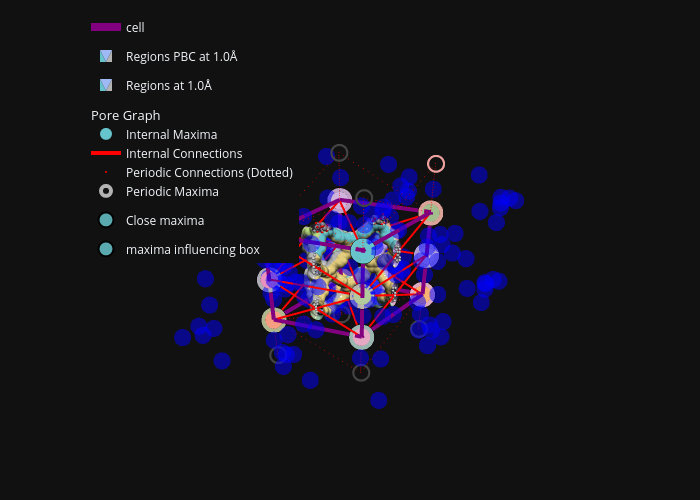

In [31]:
index = 5
fig = show_fig(collected_results_rust[index], atoms_list[index])
fig.show(renderer='png')

### Python benchmarks
Now lets do the same for python, 1. dgrid_from_atoms_cpu 2. do_periodic_segmentation

#### workflow

In [32]:
delayed_results_python= []
spacing = 0.5
for i, mat_atoms in enumerate(atoms_list):
    delayed_results_python.append(delayed(wrapper_segmentation_python)(i, mat_atoms, spacing))

Test one calc

In [33]:
delayed_results_python[0].compute()

100%|████████████████████████████████████████| 223/223 [00:04<00:00, 55.23it/s]


{'dgrid': array([[[2.49229469, 2.58497586, 2.20103135, ..., 1.77599659,
          2.11432209, 2.49229469],
         [2.48868384, 2.63794985, 2.25995579, ..., 1.77173915,
          2.11039963, 2.48868384],
         [2.55437436, 2.75580397, 2.39049091, ..., 1.85366621,
          2.18377771, 2.55437436],
         ...,
         [2.272234  , 2.28636745, 2.30837407, ..., 2.03456464,
          2.28870652, 2.272234  ],
         [2.44175599, 2.49174503, 2.21753612, ..., 1.86606827,
          2.19526973, 2.44175599],
         [2.49229445, 2.5849761 , 2.20103183, ..., 1.77599683,
          2.11432209, 2.49229493]],
 
        [[2.07108257, 2.15247844, 1.88313117, ..., 1.43224397,
          1.81119766, 2.07108257],
         [2.20271173, 2.34325089, 1.92907777, ..., 1.40430298,
          1.78680053, 2.20271173],
         [2.25670257, 2.45452895, 2.05488219, ..., 1.4753715 ,
          1.84854093, 2.25670257],
         ...,
         [1.77737407, 1.79367856, 1.83279965, ..., 1.75958965,
          1.806

### execute python benchmarks
Let's run the workflow, prettyr much same steps as in rust flow

In [ ]:
futures = dask.persist(*delayed_results_python)
progress(futures)

VBox()

  0%|                                                  | 0/118 [00:00<?, ?it/s][RAYON] current_num_threads = 16
[RAYON] current_num_threads = 16
[RAYON] current_num_threads = 16
/mnt/windows/Users/arung/shared_cloned_repos/repos/mofography_clones/mofography_rust2/mofography/mofography/helper.py:527: RuntimeWarning: overflow encountered in scalar subtract
  pos_minus[dim] = max(pos_minus[dim] - 1, 0)
[RAYON] current_num_threads = 16
/mnt/windows/Users/arung/shared_cloned_repos/repos/mofography_clones/mofography_rust2/mofography/mofography/helper.py:527: RuntimeWarning: overflow encountered in scalar subtract
  pos_minus[dim] = max(pos_minus[dim] - 1, 0)
  0%|                                                  | 0/118 [00:00<?, ?it/s]2025-09-10 23:33:40,582 - distributed.worker.memory - WARNING - Worker is at 90% memory usage. Pausing worker.  Process memory: 3.39 GiB -- Worker memory limit: 3.73 GiB
2025-09-10 23:33:40,588 - distributed.worker.memory - WARNING - Unmanaged memory use is hi

In [39]:
progress(futures)

VBox()

wait for all to finish

In [36]:
collected_futures = client.compute(futures)
collected_results_python = [f.result() if f.status=='finished' else None for f in collected_futures]
print('Collected python results, these many are None:', sum([1 for r in collected_results_python if r is None]))

Collected python results, these many are None: 1


lets check one to see if the times are there

In [37]:
print(collected_results_python[0]['version'],collected_results_python[0]['dgrid_time'], collected_results_python[0]['seg_time'])

Python 15.796898365020752 13.7125403881073


## Plot benchmark times vs Num atoms

In [53]:
# Create separate DataFrames
# Find indices where either list has None
none_indices_python = [i for i, r in enumerate(collected_results_python) if r is None]
none_indices_rust = [i for i, r in enumerate(collected_results_rust) if r is None]

# Union of all indices with None in either list
all_none_indices = sorted(set(none_indices_python) | set(none_indices_rust))

# Print which entries were None in each list
print(f"Indices with None in Python results: {none_indices_python}")
print(f"Indices with None in Rust results: {none_indices_rust}")
print(f"Union of None indices (to be removed from both): {all_none_indices}")

# Remove entries at these indices from both lists
def remove_indices(lst, indices):
    return [r for i, r in enumerate(lst) if i not in indices]

collected_results_python = remove_indices(collected_results_python, all_none_indices)
collected_results_rust = remove_indices(collected_results_rust, all_none_indices)

python_df = pd.DataFrame(collected_results_python)[['num_atoms', 'material_index', 'dgrid_time', 'seg_time', 'version']]
rust_df = pd.DataFrame(collected_results_rust)[['num_atoms', 'material_index', 'dgrid_time', 'seg_time', 'version']]

# Concatenate them vertically (stack them)
benchmark_df = pd.concat([python_df, rust_df], ignore_index=True)

print(f"Combined benchmarking data: {len(benchmark_df)} entries")
print(f"Number of unique materials: {benchmark_df['material_index'].nunique()}")
print(f"Expected entries: {benchmark_df['material_index'].nunique() * 2}")
print(benchmark_df.head(20))  # Show first 10 rows to verify Python/Rust pairs

Indices with None in Python results: []
Indices with None in Rust results: []
Union of None indices (to be removed from both): []
Combined benchmarking data: 19 entries
Number of unique materials: 10
Expected entries: 20
    num_atoms  material_index  dgrid_time   seg_time version
0         608               0   15.796898  13.712540  Python
1         627               1   14.564583  34.696111  Python
2        2288               2   25.361669  54.728079  Python
3         556               3   23.815931  11.885097  Python
4         864               4   19.484795  36.326562  Python
5         436               5   22.959427  56.341910  Python
6        1560               6   23.150911  53.974698  Python
7         684               7   24.035122  30.898619  Python
8         640               9   10.073994  21.812619  Python
9         608               0   10.040833   4.218951    Rust
10        627               1   10.762014  13.151429    Rust
11       2288               2   10.765481  14.6

### Plot the benchmarking results

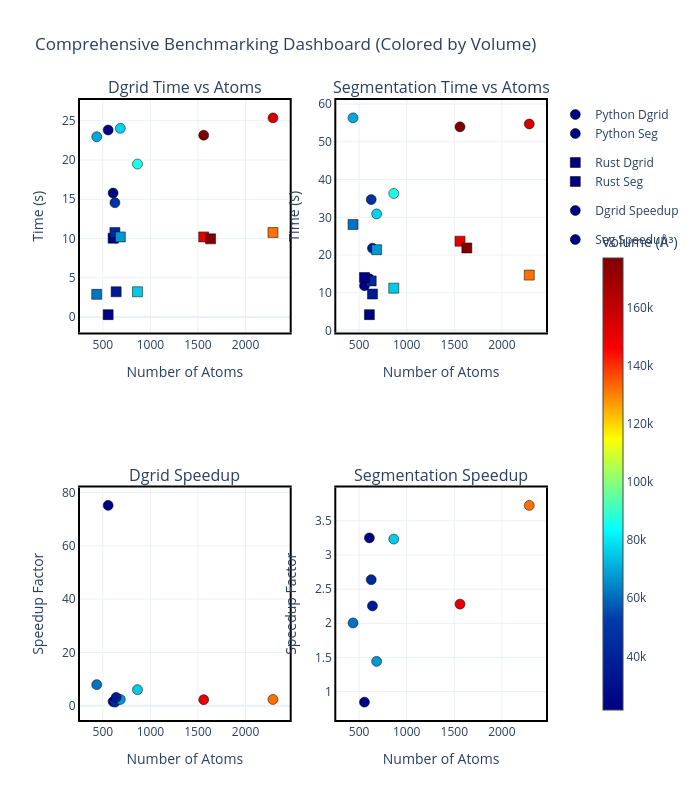

In [54]:
# Create comprehensive benchmarking plots
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
# -- MISSING: compute speedup DataFrame and melted version used later in plots
# Create speedup DataFrame comparing Python vs Rust per material
# Pivot benchmark_df so we have Python and Rust times side-by-side per material and operation
try:
    pivot = benchmark_df.pivot_table(index=['material_index','num_atoms'], columns='version', values=['dgrid_time','seg_time']).copy()
    # Flatten column MultiIndex
    pivot.columns = ['_'.join(col).strip() for col in pivot.columns.values]
    pivot = pivot.reset_index()
    # Compute speedups: Python_time / Rust_time (so >1 means Rust is faster)
    pivot['dgrid_speedup'] = pivot['dgrid_time_Python'] / pivot['dgrid_time_Rust']
    pivot['seg_speedup'] = pivot['seg_time_Python'] / pivot['seg_time_Rust']
    speedup_df = pivot[['material_index','num_atoms','dgrid_speedup','seg_speedup']].copy()
    # Melt for plotting convenience
    speedup_melted = speedup_df.melt(id_vars=['material_index','num_atoms'], value_vars=['dgrid_speedup','seg_speedup'], var_name='operation', value_name='speedup')
except Exception as e:
    # If pivot fails (missing pairs), create empty placeholders to avoid NameError later
    print('Warning computing speedup_df:', e)
    speedup_df = pd.DataFrame(columns=['material_index','num_atoms','dgrid_speedup','seg_speedup'])
    speedup_melted = pd.DataFrame(columns=['material_index','num_atoms','operation','speedup'])

# Melt the data for easier plotting
melted_df = benchmark_df.melt(id_vars=['material_index', 'num_atoms', 'version'],
                              value_vars=['dgrid_time', 'seg_time'],
                              var_name='operation', value_name='time')

# Add volume column to melted_df
melted_df['volume'] = melted_df['material_index'].apply(lambda idx: atoms_list[idx].get_volume() if atoms_list[idx] is not None else None)

# 1. Scatter plot: Time vs Number of Atoms with independent scales, colored by volume
fig1 = make_subplots(rows=1, cols=2, 
                     subplot_titles=('Dgrid Time vs Number of Atoms', 'Segmentation Time vs Number of Atoms'),
                     shared_xaxes=True)

# Add traces for dgrid_time
dgrid_data = melted_df[melted_df['operation'] == 'dgrid_time']
for version in ['Python', 'Rust']:
    version_data = dgrid_data[dgrid_data['version'] == version]
    show_colorbar = (version == 'Python')  # Show colorbar only for first trace
    fig1.add_trace(go.Scatter(x=version_data['num_atoms'], y=version_data['time'], 
                             mode='markers', name=f'{version} Dgrid',
                             marker=dict(color=version_data['volume'], 
                                        colorscale='jet', 
                                        size=10,
                                        symbol='circle' if version == 'Python' else 'square',
                                        line=dict(color='black', width=0.5),
                                        colorbar=dict(title="Volume (Å³)", 
                                                     x=1.1, y=0.4, 
                                                     orientation='v',
                                                     len=0.8, thickness=20) if show_colorbar else None)),
                   row=1, col=1)

# Add traces for seg_time
seg_data = melted_df[melted_df['operation'] == 'seg_time']
for version in ['Python', 'Rust']:
    version_data = seg_data[seg_data['version'] == version]
    fig1.add_trace(go.Scatter(x=version_data['num_atoms'], y=version_data['time'], 
                             mode='markers', name=f'{version} Segmentation',
                             marker=dict(color=version_data['volume'], 
                                        colorscale='jet', 
                                        size=10,
                                        symbol='circle' if version == 'Python' else 'square',
                                        line=dict(color='black', width=0.5))),
                   row=1, col=2)

fig1.update_layout(height=500, title_text="Benchmarking: Python vs Rust Performance (Colored by Volume)",
                   template='plotly_white', showlegend=True)
fig1.update_xaxes(title_text="Number of Atoms", row=1, col=1)
fig1.update_xaxes(title_text="Number of Atoms", row=1, col=2)
fig1.update_yaxes(title_text="Time (seconds)", row=1, col=1)
fig1.update_yaxes(title_text="Time (seconds)", row=1, col=2)

# Add borders to subplots
fig1.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True)
fig1.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True)

# fig1.show()

# 2. Box plot: Distribution of times by operation and version (keeping original coloring)
fig2 = px.box(melted_df, x='operation', y='time', color='version',
              title='Time Distribution by Operation and Implementation',
              labels={'operation': 'Operation', 'time': 'Time (seconds)',
                      'version': 'Implementation'},
              template='plotly_white',
              color_discrete_map={'Python': 'blue', 'Rust': 'red'})

fig2.update_layout(height=500, font=dict(size=12))
fig2.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True)
fig2.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True)

fig2.show()

# 3. Performance ratio plot (Rust speedup) colored by volume
speedup_melted['volume'] = speedup_melted['material_index'].apply(lambda idx: atoms_list[idx].get_volume() if atoms_list[idx] is not None else None)

fig3 = px.scatter(speedup_melted, x='num_atoms', y='speedup', color='volume',
                  title='Rust Speedup Factor vs Number of Atoms (Colored by Volume)',
                  labels={'num_atoms': 'Number of Atoms', 'speedup': 'Speedup (Python time / Rust time)',
                          'operation': 'Operation'},
                  template='plotly_white',
                  color_continuous_scale='jet')

fig3.update_traces(marker=dict(size=10))  # Set marker size to 10

fig3.add_hline(y=1, line_dash="dash", line_color="red", annotation_text="No speedup")
fig3.update_layout(height=500, font=dict(size=12))
fig3.update_xaxes(showline=True, linewidth=2, linecolor='black', mirror=True)
fig3.update_yaxes(showline=True, linewidth=2, linecolor='black', mirror=True)

# Update colorbar position
fig3.update_coloraxes(colorbar=dict(title="Volume (Å³)", orientation='v', y=0.4, x=1.1, len=0.8))

fig3.show()

# 4. Combined subplot view with professional styling, colored by volume
fig4 = make_subplots(rows=2, cols=2,
                     subplot_titles=('Dgrid Time vs Atoms', 'Segmentation Time vs Atoms',
                                   'Dgrid Speedup', 'Segmentation Speedup'),
                     specs=[[{"secondary_y": False}, {"secondary_y": False}],
                            [{"secondary_y": False}, {"secondary_y": False}]])

# Add volume to benchmark_df for coloring
benchmark_df['volume'] = benchmark_df['material_index'].apply(lambda idx: atoms_list[idx].get_volume() if atoms_list[idx] is not None else None)

# Add volume to speedup_df for coloring
speedup_df['volume'] = speedup_df['material_index'].apply(lambda idx: atoms_list[idx].get_volume() if atoms_list[idx] is not None else None)

# Add traces for time comparisons
for version in ['Python', 'Rust']:
    data = benchmark_df[benchmark_df['version'] == version]
    symbol = 'circle' if version == 'Python' else 'square'
    show_colorbar = (version == 'Python')  # Show colorbar only for first trace
    fig4.add_trace(go.Scatter(x=data['num_atoms'], y=data['dgrid_time'], mode='markers',
                             name=f'{version} Dgrid', legendgroup=version,
                             marker=dict(color=data['volume'], colorscale='jet', 
                                        size=10, symbol=symbol,
                                        line=dict(color='black', width=0.5),
                                        colorbar=dict(title="Volume (Å³)", 
                                                     x=1.1, y=0.4, 
                                                     orientation='v',
                                                     len=0.8, thickness=20) if show_colorbar else None)), row=1, col=1)
    fig4.add_trace(go.Scatter(x=data['num_atoms'], y=data['seg_time'], mode='markers',
                             name=f'{version} Seg', legendgroup=version,
                             marker=dict(color=data['volume'], colorscale='jet', 
                                        size=10, symbol=symbol,
                                        line=dict(color='black', width=0.5))), row=1, col=2)

# Add traces for speedup
fig4.add_trace(go.Scatter(x=speedup_df['num_atoms'], y=speedup_df['dgrid_speedup'],
                         mode='markers', name='Dgrid Speedup',
                         marker=dict(color=speedup_df['volume'], colorscale='jet', 
                                    size=10, line=dict(color='black', width=0.5))), row=2, col=1)
fig4.add_trace(go.Scatter(x=speedup_df['num_atoms'], y=speedup_df['seg_speedup'],
                         mode='markers', name='Seg Speedup',
                         marker=dict(color=speedup_df['volume'], colorscale='jet', 
                                    size=10, line=dict(color='black', width=0.5))), row=2, col=2)

fig4.update_layout(height=800, title_text="Comprehensive Benchmarking Dashboard (Colored by Volume)",
                   template='plotly_white', font=dict(size=12))

# Update axes with borders
for row in [1, 2]:
    for col in [1, 2]:
        fig4.update_xaxes(title_text="Number of Atoms", row=row, col=col,
                         showline=True, linewidth=2, linecolor='black', mirror=True)
        if row == 1:
            fig4.update_yaxes(title_text="Time (s)", row=row, col=col,
                             showline=True, linewidth=2, linecolor='black', mirror=True)
        else:
            fig4.update_yaxes(title_text="Speedup Factor", row=row, col=col,
                             showline=True, linewidth=2, linecolor='black', mirror=True)

fig4.show(renderer='png')

## Summary
- 

Here are the key findings and recommendations from the benchmarking runs:

- Rayon parallelism: Rayon parallelizes work across threads inside Rust code by splitting tasks across worker threads (set by RAYON_NUM_THREADS). It gives good strong-scaling for compute-bound pieces when enough CPU cores are available.
- Dgrid calculation: This step is largely compute-bound (not memory-bound) for the typical dgrid sizes here — adding more workers/threads usually reduces time (more threads -> more speed) until you saturate cores.
- Segmentation step: Segmentation is memory-bandwidth sensitive. Increasing threads beyond a certain point yields diminishing returns or even slows things down; there is often a modest sweet-spot (fewer threads) that maximizes throughput.
- Practical HTS strategy: Instead of maximizing threads per material, fix a modest number of Rayon threads (for example 8 or 16) inside the Rust code and run many independent materials in parallel (e.g. 1 material per core). This avoids memory-bandwidth contention while keeping dgrid compute parallelism effective.
- Recommended settings: Export RAYON_NUM_THREADS to a modest value (4 or 8 or 16) before running batch jobs, ensure all worker processes for a high-throughput run are on the same node, and use one process per core to maximize node-wide throughput for 1–2000-atom materials.
- Summary: For HTS with many small-to-medium materials, you'll get best wall-clock throughput by keeping per-material thread counts moderate (fix Rayon threads) and parallelizing across materials at the process/core level rather than pushing thread counts very high inside each job.

These recommendations balance CPU utilization and memory-bandwidth limits and are easy to apply: set `RAYON_NUM_THREADS=8` (or 16), start multiple processes (1 per core), and process different materials concurrently using Dask as shown above.
